# 01 · Retention and engagement

**Question.** How many players come back, and how does it relate to how much they play?
**Answer.** 44.5% of players come back on day 1 and 18.6% on day 7. D7 retention rises from 0.7% for players who never played a round to 55.0% for those who played more than 50. This is a correlation, and partly mechanical: rounds are counted over 14 days, so a player who returns on day 7 has more days left to play.
**Method.** The queries are the files of `sql/`; this notebook only runs and formats them.

In [1]:
import matplotlib.pyplot as plt

from game_players.database import connect, run_sql

con = connect()


def as_pct(df):
    """Show rate columns (fractions) as percentages."""
    return df.style.format({c: "{:.2%}" for c in df.columns if c.startswith("retention")}).hide(axis="index")

## 1. Headline retention

In [2]:
as_pct(run_sql(con, "01_kpis.sql"))

players,retained_d1,retained_d7,retention_d1,retention_d7
90189,40153,16781,44.52%,18.61%


## 2. Retention by A/B group

Descriptive only; the test is in notebook 02.

In [3]:
as_pct(run_sql(con, "02_retention_by_version.sql"))

version,players,retained_d1,retained_d7,retention_d1,retention_d7
gate_30,44700,20034,8502,44.82%,19.02%
gate_40,45489,20119,8279,44.23%,18.20%


## 3. D7 retention by rounds played

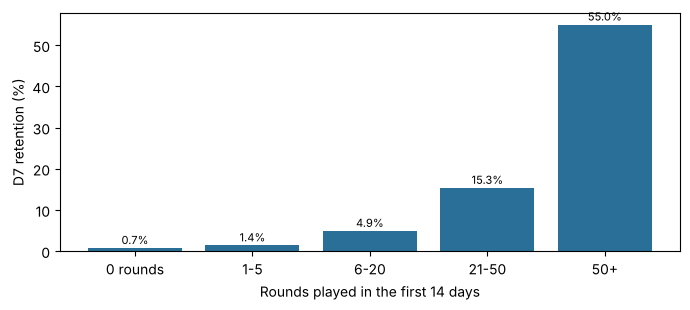

sort_order,band,players,retention_d7
1,0 rounds,3994,0.73%
2,1-5,20723,1.37%
3,6-20,25085,4.89%
4,21-50,17575,15.34%
5,50+,22812,55.00%


In [4]:
bands = run_sql(con, "03_engagement_bands.sql")
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.bar(bands["band"], 100 * bands["retention_d7"], color="#2a6f97")
for i, v in enumerate(bands["retention_d7"]):
    ax.text(i, 100 * v + 1, f"{v:.1%}", ha="center", fontsize=8)
ax.set_xlabel("Rounds played in the first 14 days")
ax.set_ylabel("D7 retention (%)")
plt.tight_layout()
plt.show()
as_pct(bands)

## 4. D7 retention by quartile of rounds played

In [5]:
as_pct(run_sql(con, "04_engagement_quartiles.sql"))

quartile,players,min_rounds,max_rounds,retention_d7
1,22548,0,5,1.19%
2,22547,5,16,3.93%
3,22547,16,51,13.97%
4,22547,51,49854,55.34%


## 5. Extreme values

In [6]:
run_sql(con, "05_top_players_by_rounds.sql")

,userid,version,sum_gamerounds
0,6390605,gate_30,49854
1,871500,gate_30,2961
2,3271615,gate_40,2640
3,4832608,gate_30,2438
4,5346171,gate_40,2294
5,5133952,gate_30,2251
6,9640085,gate_30,2156
7,4090246,gate_40,2124
8,9791599,gate_40,2063
9,725080,gate_40,2015


One player has 49,854 rounds, about 17 times the next one: error, bot or real player, the cause is unknown. Kept in retention rates (1 player out of 90,189 changes nothing), excluded from any statistic on the number of rounds.

## Findings

- **Retention.** 44.52% of the 90,189 players come back on day 1, 18.61% on day 7.
- **By group.** gate_30: 44.82% (D1) and 19.02% (D7); gate_40: 44.23% and 18.20%. Notebook 02 tests whether these gaps are real.
- **Engagement.** D7 retention is 0.7% for the 3,994 players who never played a round, then 1.4%, 4.9%, 15.3% and 55.0% across the bands. The relation is strong but not causal: playing a lot is partly a consequence of coming back.
- **Outlier.** One player with 49,854 rounds, kept in rates only.

In [7]:
con.close()